In [1]:
# .plot.bar()
# .plot.barh()

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

<Axes: >

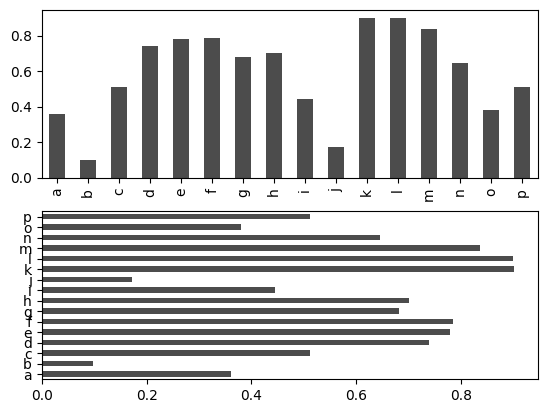

In [3]:
fig, axes = plt.subplots(2, 1)

data = pd.Series(np.random.uniform(size=16),
                 index=list('abcdefghijklmnop'))

data.plot.bar(ax=axes[0], 
              color='black', alpha=0.7)
data.plot.barh(ax=axes[1],
               color='black', alpha=0.7)

In [4]:
df = pd.DataFrame(np.random.uniform(size=(6, 4)),
                  index=['one', 'two', 'three', 'four', 'five', 'six'],
                  columns=pd.Index(['A', 'B', 'C', 'D'], name='Genus'))

df

Genus,A,B,C,D
one,0.303883,0.964129,0.623469,0.592250
two,0.854691,0.616109,0.117612,0.788468
three,0.203151,0.866047,0.896582,0.611731
four,0.886818,0.480523,0.925610,0.028028
five,0.054009,0.994348,0.457136,0.305465
six,0.527072,0.449075,0.468679,0.387433


<Axes: >

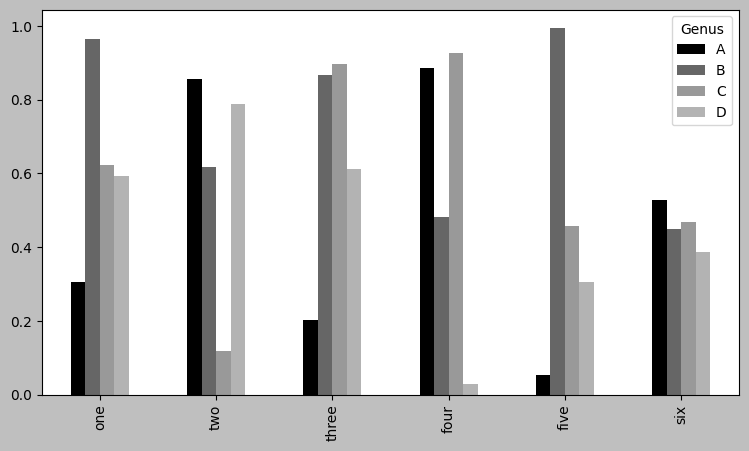

In [5]:
plt.style.use('grayscale')

df.plot.bar(figsize=(9, 5))

<Axes: >

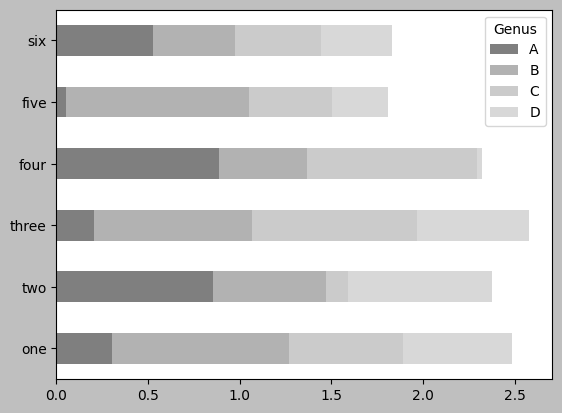

In [6]:
df.plot.barh(stacked=True, alpha=0.5)

In [7]:
# pandas.crosstab()

In [8]:
path = '../../../_data_py_for_da/'

In [9]:
tips = pd.read_csv(path+'examples/tips.csv')
tips.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4


In [10]:
party_counts = pd.crosstab(tips['day'], tips['size'])
party_counts

size,1,2,3,4,5,6
day,,,,,,
Fri,1,16,1,1,0,0
Sat,2,53,18,13,1,0
Sun,0,39,15,18,3,1
Thur,1,48,4,5,1,3


In [11]:
party_counts = party_counts.reindex(index=['Thur', 'Fri', 'Sat', 'Sun'])
party_counts

size,1,2,3,4,5,6
day,,,,,,
Thur,1,48,4,5,1,3
Fri,1,16,1,1,0,0
Sat,2,53,18,13,1,0
Sun,0,39,15,18,3,1


In [12]:
# removing sizes 1 and 6
party_counts = party_counts.loc[:, 2:5]

In [13]:
party_pcts = party_counts.div(party_counts.sum(axis='columns'),
                              axis='index')
party_pcts

size,2,3,4,5
day,,,,
Thur,0.827586,0.068966,0.086207,0.017241
Fri,0.888889,0.055556,0.055556,0.000000
Sat,0.623529,0.211765,0.152941,0.011765
Sun,0.520000,0.200000,0.240000,0.040000


<Axes: xlabel='day'>

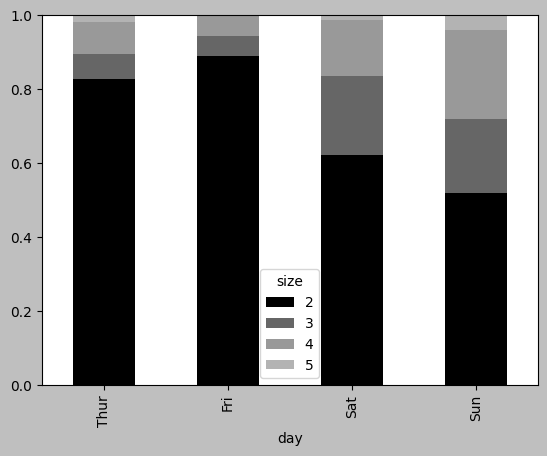

In [14]:
party_pcts.plot.bar(stacked=True)

In [15]:
# seaborn.barplot()

In [16]:
import seaborn as sns

In [17]:
tips.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4


In [18]:
tips['tip_pct'] = tips['tip'] / (tips['total_bill'] - tips['tip'])

tips.head()

,total_bill,tip,smoker,day,time,size,tip_pct
0,16.99,1.01,No,Sun,Dinner,2,0.063204
1,10.34,1.66,No,Sun,Dinner,3,0.191244
2,21.01,3.50,No,Sun,Dinner,3,0.199886
3,23.68,3.31,No,Sun,Dinner,2,0.162494
4,24.59,3.61,No,Sun,Dinner,4,0.172069


<Axes: xlabel='tip_pct', ylabel='day'>

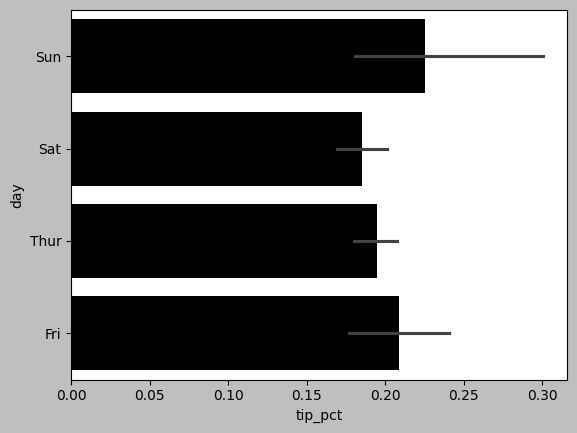

In [19]:
sns.barplot(x='tip_pct', y='day', 
            data=tips, orient='h')

<Axes: xlabel='tip_pct', ylabel='day'>

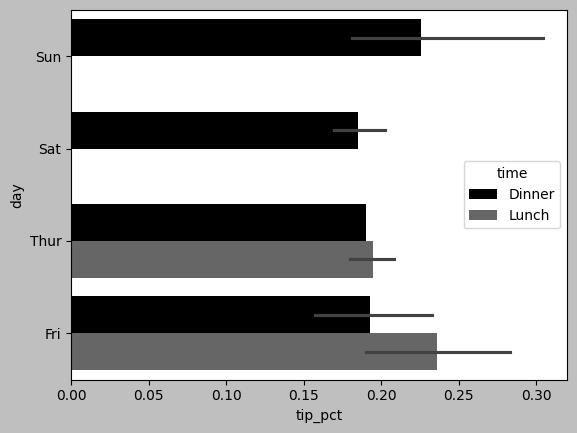

In [20]:
sns.barplot(x='tip_pct', y='day', hue='time',
            data=tips, orient='h')